# Coffee Roast Classification
Implementasi **Multimodal Classification of Coffee Roast Level Using Bean Color Images and Roasting Crack Sound**, untuk tugas mata kuliah Rekayasa Fitur dan Pengenalan Pola, Magister Ilmu Komputer, Universitas Gadjah Mada.

Anggota Kelompok:
1. Alif Ilman Nafian (25/572957/PPA/07203)
2. Kevin Pratama (25/574311/PPA/07241)
3. Maulana Yusuf Habibi (25/575185/PPA/07275)
4. Alfi Maulana Akbar (25/574622/PPA/07253)

Jalankan berurutan dengan **Run all**.

In [1]:
import sys
from pathlib import Path
import os
import subprocess
assert sys.version_info >= (3,12), 'Memerlukan Python 3.12 atau lebih baru'
REPOSITORY = 'https://github.com/fimln/rfpp-project.git'
REVISION = 'main'  # Ganti dengan commit SHA untuk mengulang versi yang sama.
ROOT = Path('/content/rfpp-project')
RUN_COMPLETED = False


In [2]:
if not (ROOT / '.git').exists():
    subprocess.run(['git', 'clone', '--depth', '1', REPOSITORY, str(ROOT)], check=True)
subprocess.run(['git', '-C', str(ROOT), 'fetch', '--depth', '1', 'origin', REVISION], check=True)
subprocess.run(['git', '-C', str(ROOT), 'checkout', '--detach', 'FETCH_HEAD'], check=True)
os.chdir(ROOT)
SOURCE_COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
print('Source commit:', SOURCE_COMMIT)
print('Requirements:', ROOT / 'requirements.txt')


Source commit: 63a6fedd585c6ae1ff820d40fc9e1e03be261ec1
Requirements: /content/rfpp-project/requirements.txt


In [3]:
%pip install -q -r requirements.txt
!apt-get -qq update
!apt-get -qq install -y git-lfs
import subprocess
subprocess.run(['git','lfs','install'],check=True)


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package git-lfs.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...


CompletedProcess(args=['git', 'lfs', 'install'], returncode=0)

In [4]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'coffee.download', '--destination', 'data'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'coffee.download', '--destination', 'data'], returncode=0)

In [5]:
# Invalidate previous results before starting this run.
RUN_COMPLETED = False
metrics_path = Path('outputs/metrics.json')
metrics_path.unlink(missing_ok=True)
subprocess.run([sys.executable,'-m','pytest','-q'],check=True)
# False: baseline yang diuji lokal; True: tambah perbandingan CNN.
RUN_CNN = False
if RUN_CNN:
    subprocess.run([sys.executable,'-m','pip','install','torch','torchvision'],check=True)
command = [sys.executable,'-m','coffee.train','--images','data/gpiosenka_coffee-bean-dataset-resized-224-x-224','--audio','data/audio-lfs/datasets']
if RUN_CNN:
    command.append('--cnn')
subprocess.run(command,check=True)
Path('outputs/source_commit.txt').write_text(SOURCE_COMMIT + '\n', encoding='utf-8')
RUN_COMPLETED = True


In [6]:
import json
if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Jalankan sel training hingga selesai pada sesi ini sebelum menampilkan hasil.')
metrics = json.loads(Path('outputs/metrics.json').read_text())
for modality, result in metrics.items():
    if isinstance(result, dict):
        print(modality, 'selected:',result['selected'], 'test accuracy:',result['test_accuracy'])
        print('Audit:',result['audit'])
print(metrics['fusion'])


image selected: svm test accuracy: 0.9825
Audit: {'counts': {'test': 400, 'train': 614, 'val': 180}, 'cross_split_identical_files': 0, 'train_test_trial_overlap': []}
audio selected: rf test accuracy: 0.9096671949286846
Audit: {'counts': {'test': 631, 'val': 592, 'train': 2334}, 'cross_split_identical_files': 0, 'train_test_trial_overlap': ['1yunnan', '2yunnan', '3ethiopia', '4ethiopia', '5kenya', '6kenya', '7kenya', '8ethiopia']}
Not evaluated: no paired ground truth. Validation weights are heuristic across different tasks.


## Visualisasi hasil run ini
Semua angka berikut dibaca dari `outputs/metrics.json` yang baru dihasilkan training pada sesi ini. Tidak ada hasil referensi atau angka lokal yang ditanam. Macro F1 memberi bobot sama pada setiap kelas. Gambar dan audio merupakan tugas berbeda, sehingga selisih skornya tidak membuktikan keunggulan satu modalitas.


| Modalitas | Model terpilih | Jumlah test | Akurasi test | Macro F1 test |
| --- | --- | ---: | ---: | ---: |
| Gambar | SVM | 400 | 98.25% | 98.25% |
| Audio | RF | 631 | 90.97% | 87.81% |

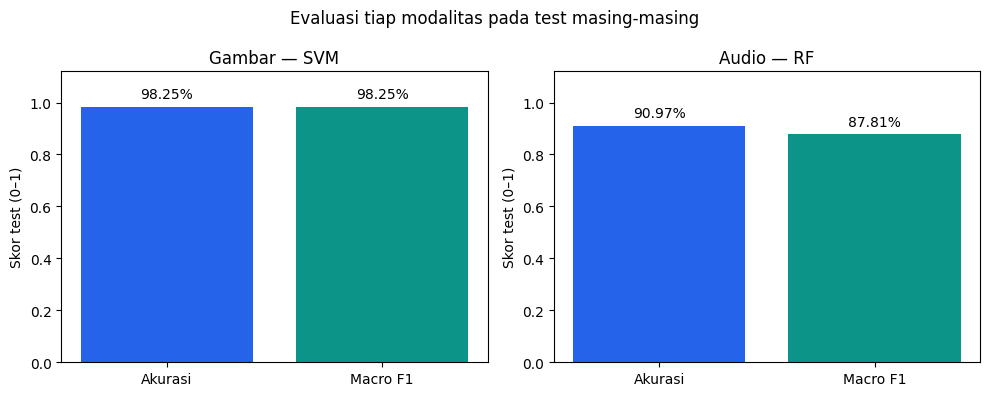

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Training run ini belum berhasil selesai.')
metrics = json.loads(Path('outputs/metrics.json').read_text())
results = {name: result for name, result in metrics.items() if isinstance(result, dict)}
titles = {'image': 'Gambar', 'audio': 'Audio', 'image_cnn': 'Gambar CNN'}
table = ['| Modalitas | Model terpilih | Jumlah test | Akurasi test | Macro F1 test |',
         '| --- | --- | ---: | ---: | ---: |']
for name, result in results.items():
    table.append(f"| {titles.get(name, name)} | {result['selected'].upper()} | {result['audit']['counts']['test']} | {result['test_accuracy']:.2%} | {result['test_report']['macro avg']['f1-score']:.2%} |")
display(Markdown('\n'.join(table)))

fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4), squeeze=False)
for ax, (name, result) in zip(axes[0], results.items()):
    scores = [result['test_accuracy'], result['test_report']['macro avg']['f1-score']]
    bars = ax.bar(['Akurasi', 'Macro F1'], scores, color=['#2563eb', '#0d9488'])
    ax.set_ylim(0, 1.12)
    ax.set_title(titles.get(name, name) + ' — ' + result['selected'].upper())
    ax.set_ylabel('Skor test (0–1)')
    ax.bar_label(bars, labels=[f'{score:.2%}' for score in scores], padding=4)
fig.suptitle('Evaluasi tiap modalitas pada test masing-masing')
fig.tight_layout()
fig.savefig('outputs/test_scores.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)


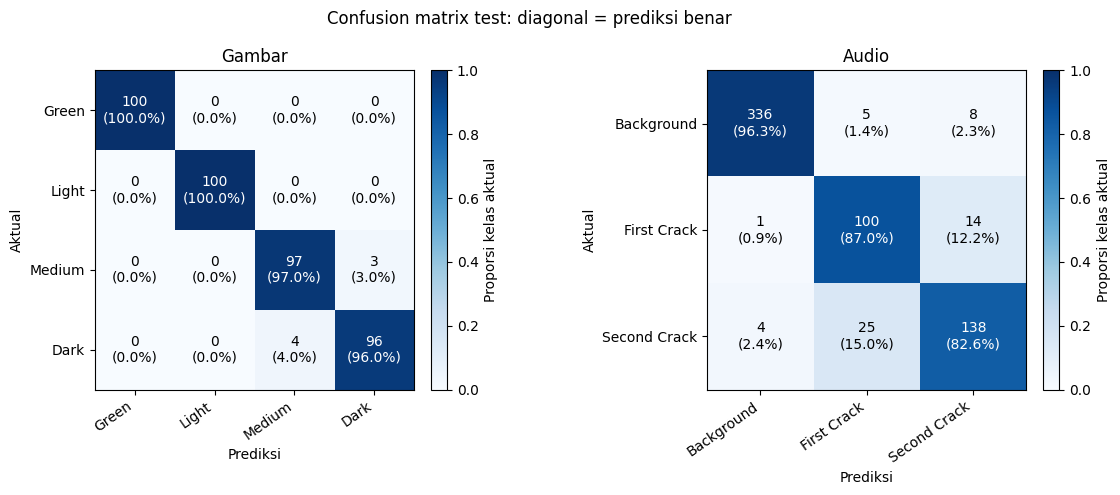

In [8]:
# Warna menunjukkan persentase per kelas aktual; teks menunjukkan jumlah file.
if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Training run ini belum berhasil selesai.')
fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5), squeeze=False)
for ax, (name, result) in zip(axes[0], results.items()):
    labels = [key for key, value in result['test_report'].items()
              if isinstance(value, dict) and key not in ('macro avg', 'weighted avg', 'micro avg')]
    matrix = np.asarray(result['confusion_matrix'])
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True),
                           out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
    im = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    for row in range(len(labels)):
        for col in range(len(labels)):
            ax.text(col, row, f'{matrix[row, col]}\n({normalized[row, col]:.1%})',
                    ha='center', va='center', color='white' if normalized[row, col] > .5 else 'black')
    ax.set_xticks(range(len(labels)), labels, rotation=35, ha='right')
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    ax.set_title(titles.get(name, name))
    fig.colorbar(im, ax=ax, fraction=.046, pad=.04, label='Proporsi kelas aktual')
fig.suptitle('Confusion matrix test: diagonal = prediksi benar')
fig.tight_layout()
fig.savefig('outputs/test_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)


In [9]:
if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Training run ini belum berhasil selesai.')
lines = ['### Kesimpulan run ini', '']
for name, result in results.items():
    matrix = np.asarray(result['confusion_matrix'])
    labels = [key for key, value in result['test_report'].items()
              if isinstance(value, dict) and key not in ('macro avg', 'weighted avg', 'micro avg')]
    total = int(matrix.sum())
    correct = int(np.trace(matrix))
    lines.append(f"- **{titles.get(name, name)}**: {correct}/{total} prediksi benar, akurasi **{result['test_accuracy']:.2%}**, macro F1 **{result['test_report']['macro avg']['f1-score']:.2%}**. Model {result['selected'].upper()} dipilih dari validasi.")
    mistakes = matrix.copy()
    np.fill_diagonal(mistakes, 0)
    if mistakes.max() > 0:
        row, col = np.unravel_index(mistakes.argmax(), mistakes.shape)
        lines.append(f"  Kesalahan terbanyak (salah satu jika seri): **{labels[row]} → {labels[col]}**, {mistakes[row, col]} file.")
    overlap = result['audit']['train_test_trial_overlap']
    if overlap:
        lines.append(f"  Ada **{len(overlap)} trial** yang beririsan antara train dan test; generalisasi ke trial baru belum dibuktikan.")
    duplicates = result['audit']['cross_split_identical_files']
    if duplicates:
        lines.append(f"  **Peringatan:** ditemukan {duplicates} salinan identik lintas split; hasil berisiko bocor.")
lines.extend(['', '**Fusion pada pasangan roasting nyata belum dievaluasi** karena tidak tersedia test berpasangan asli. Skor di atas adalah evaluasi masing-masing modalitas. Simulasi Light–Dark berbasis pasangan sintetis ditampilkan pada bagian berikutnya.'])
conclusion = '\n'.join(lines)
display(Markdown(conclusion))
Path('outputs/conclusion.md').write_text(conclusion, encoding='utf-8')


### Kesimpulan run ini

- **Gambar**: 393/400 prediksi benar, akurasi **98.25%**, macro F1 **98.25%**. Model SVM dipilih dari validasi.
  Kesalahan terbanyak (salah satu jika seri): **Dark → Medium**, 4 file.
- **Audio**: 574/631 prediksi benar, akurasi **90.97%**, macro F1 **87.81%**. Model RF dipilih dari validasi.
  Kesalahan terbanyak (salah satu jika seri): **Second Crack → First Crack**, 25 file.
  Ada **8 trial** yang beririsan antara train dan test; generalisasi ke trial baru belum dibuktikan.

**Fusion pada pasangan roasting nyata belum dievaluasi** karena tidak tersedia test berpasangan asli. Skor di atas adalah evaluasi masing-masing modalitas. Simulasi Light–Dark berbasis pasangan sintetis ditampilkan pada bagian berikutnya.

746

## Simulasi fusion Light–Dark: pasangan sintetis
Pairing otomatis berdasarkan label: Light–First Crack dan Dark–Second Crack, hanya dalam split yang sama. Green/Medium/Background tidak digunakan di simulasi ini. Model unimodal tetap model empat/tiga kelas; probabilitas dinormalisasi ulang ke dua kelas. Bobot fusion ditentukan dari validasi, bukan test. Semua seed dilaporkan.

**Bukan pasangan batch roasting nyata.** Label digunakan untuk membuat kedua modalitas konsisten kelasnya; hasil hanya berlaku pada simulasi ini. Standar deviasi antar-seed bukan confidence interval. Diagram same batch/stage belum terpenuhi dan irisan trial audio tetap ada.


In [10]:
import joblib
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from coffee.features import image_features, audio_features

SIM_COMPLETED = False
if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Jalankan training pada sesi ini sampai selesai.')
Path('outputs/synthetic_fusion.json').unlink(missing_ok=True)
SEEDS = [42, 43, 44, 45, 46]
LABELS = ['Light', 'Dark']
pools = {}
for modality, selected, feature in [('image', ['Light', 'Dark'], image_features),
                                    ('audio', ['First Crack', 'Second Crack'], audio_features)]:
    bundle = joblib.load(f'outputs/{modality}.joblib')
    manifest = json.loads(Path(f'outputs/{modality}_manifest.json').read_text())
    columns = [bundle['classes'].index(label) for label in selected]
    for split in ['val', 'test']:
        for label, column in enumerate(columns):
            rows = [row for row in manifest if row['split'] == split and row['label'] == column]
            if not rows:
                raise ValueError(f'Tidak ada data {modality}/{split}/{selected[label]}')
            probabilities = bundle['model'].predict_proba([feature(row['path']) for row in rows])[:, columns]
            probabilities /= probabilities.sum(axis=1, keepdims=True)
            pools[modality, split, label] = (rows, probabilities)
print('Probabilitas validasi dan test siap; tidak ada pelatihan ulang.')


Probabilitas validasi dan test siap; tidak ada pelatihan ulang.


In [11]:
if not globals().get('RUN_COMPLETED', False):
    raise RuntimeError('Training run ini harus berhasil terlebih dahulu.')
simulation = []
for seed in SEEDS:
    paired = {}
    for split in ['val', 'test']:
        rng = np.random.default_rng(seed + (10000 if split == 'test' else 0))
        count = min(len(pools[modality, split, label][0])
                    for modality in ['image', 'audio'] for label in range(2))
        image_p, audio_p, truth, pairs = [], [], [], []
        for label in range(2):
            ir, ip = pools['image', split, label]
            ar, ap = pools['audio', split, label]
            ii, ai = rng.permutation(len(ir))[:count], rng.permutation(len(ar))[:count]
            image_p.extend(ip[ii]); audio_p.extend(ap[ai]); truth.extend([label] * count)
            pairs.extend({'seed': seed, 'split': split, 'label': LABELS[label],
                          'image': ir[i]['path'], 'audio': ar[a]['path']} for i, a in zip(ii, ai))
        Path(f'outputs/synthetic_pairs_{split}_{seed}.json').write_text(json.dumps(pairs, indent=2), encoding='utf-8')
        paired[split] = (np.asarray(image_p), np.asarray(audio_p), np.asarray(truth))
    vi, va, vy = paired['val']
    weights = sorted(np.linspace(0, 1, 21), key=lambda w: abs(w - .5))
    weight = max(weights, key=lambda w: f1_score(vy, (w * vi + (1-w) * va).argmax(axis=1), average='macro'))
    ti, ta, ty = paired['test']
    result = {'seed': seed, 'image_weight': float(weight), 'test_pairs': len(ty), 'methods': {}}
    for method, probability in [('Gambar', ti), ('Audio', ta), ('Fusion sintetis', weight*ti + (1-weight)*ta)]:
        prediction = probability.argmax(axis=1)
        result['methods'][method] = {'accuracy': float(accuracy_score(ty, prediction)),
                                    'macro_f1': float(f1_score(ty, prediction, average='macro')),
                                    'confusion_matrix': confusion_matrix(ty, prediction, labels=[0, 1]).tolist()}
    simulation.append(result)
Path('outputs/synthetic_fusion.json').write_text(json.dumps({'limitation': 'Class-conditioned synthetic pairs; not same-batch roast evaluation', 'runs': simulation}, indent=2), encoding='utf-8')
SIM_COMPLETED = True


| Seed | Bobot gambar | Jumlah test | F1 gambar | F1 audio | F1 fusion sintetis |
| --- | ---: | ---: | ---: | ---: | ---: |
| 42 | 0.50 | 200 | 100.00% | 85.99% | 100.00% |
| 43 | 0.50 | 200 | 100.00% | 83.99% | 100.00% |
| 44 | 0.50 | 200 | 100.00% | 85.48% | 100.00% |
| 45 | 0.50 | 200 | 100.00% | 85.50% | 100.00% |
| 46 | 0.50 | 200 | 100.00% | 86.00% | 100.00% |

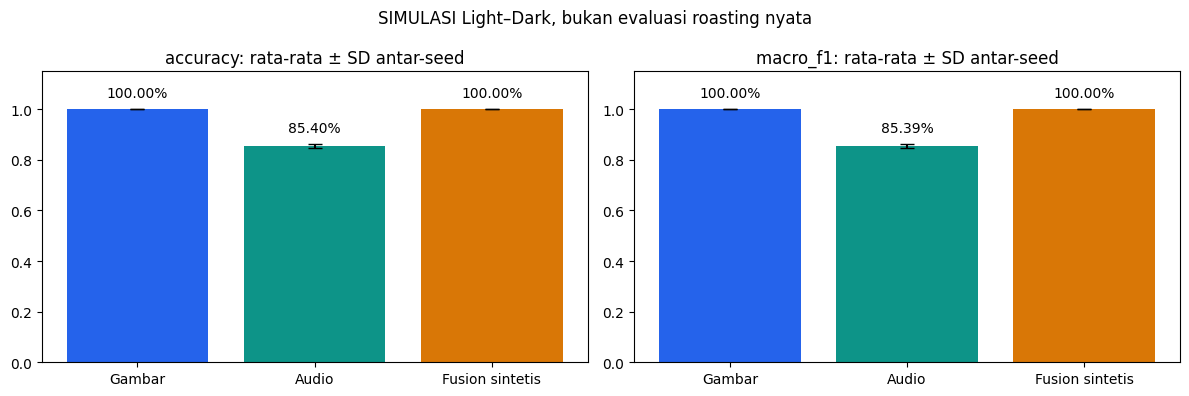

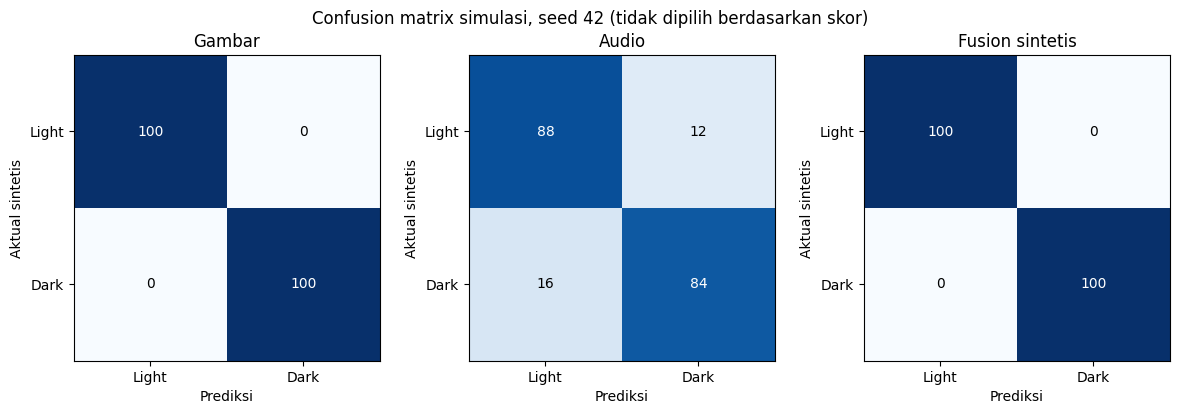

### Kesimpulan simulasi run ini

Macro F1 rata-rata fusion sintetis: **100.00%**. Selisih terhadap baseline unimodal terbaik: **+0.00 poin persentase**. Hasil ini hanya untuk pasangan sintetis yang dibentuk berdasarkan label, bukan bukti peningkatan pada roasting nyata. Variasi antar-seed memakai ulang file test dan bukan confidence interval.

344

In [12]:
if not globals().get('RUN_COMPLETED', False) or not globals().get('SIM_COMPLETED', False):
    raise RuntimeError('Training dan simulasi run ini harus berhasil terlebih dahulu.')
methods = ['Gambar', 'Audio', 'Fusion sintetis']
table = ['| Seed | Bobot gambar | Jumlah test | F1 gambar | F1 audio | F1 fusion sintetis |',
         '| --- | ---: | ---: | ---: | ---: | ---: |']
for run in simulation:
    values = [f"{run['methods'][method]['macro_f1']:.2%}" for method in methods]
    table.append(f"| {run['seed']} | {run['image_weight']:.2f} | {run['test_pairs']} | " + ' | '.join(values) + ' |')
display(Markdown('\n'.join(table)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['accuracy', 'macro_f1']):
    values = np.asarray([[run['methods'][method][metric] for method in methods] for run in simulation])
    bars = ax.bar(methods, values.mean(axis=0), yerr=values.std(axis=0), capsize=5,
                  color=['#2563eb', '#0d9488', '#d97706'])
    ax.bar_label(bars, labels=[f'{x:.2%}' for x in values.mean(axis=0)], padding=7)
    ax.set_ylim(0, 1.15)
    ax.set_title(metric + ': rata-rata ± SD antar-seed')
fig.suptitle('SIMULASI Light–Dark, bukan evaluasi roasting nyata')
fig.tight_layout()
fig.savefig('outputs/synthetic_fusion_scores.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, method in zip(axes, methods):
    matrix = np.asarray(simulation[0]['methods'][method]['confusion_matrix'])
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max(1, matrix.sum(axis=1).max()))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.sum(axis=1).max()/2 else 'black')
    ax.set_xticks([0, 1], LABELS); ax.set_yticks([0, 1], LABELS)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual sintetis'); ax.set_title(method)
fig.suptitle(f"Confusion matrix simulasi, seed {SEEDS[0]} (tidak dipilih berdasarkan skor)")
fig.tight_layout()
fig.savefig('outputs/synthetic_fusion_confusion.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close(fig)
means = {method: np.mean([run['methods'][method]['macro_f1'] for run in simulation]) for method in methods}
delta = means['Fusion sintetis'] - max(means['Gambar'], means['Audio'])
summary = (f"### Kesimpulan simulasi run ini\n\nMacro F1 rata-rata fusion sintetis: **{means['Fusion sintetis']:.2%}**. "
           f"Selisih terhadap baseline unimodal terbaik: **{delta*100:+.2f} poin persentase**. "
           'Hasil ini hanya untuk pasangan sintetis yang dibentuk berdasarkan label, bukan bukti peningkatan pada roasting nyata. '
           'Variasi antar-seed memakai ulang file test dan bukan confidence interval.')
display(Markdown(summary))
Path('outputs/synthetic_conclusion.md').write_text(summary, encoding='utf-8')


## Inferensi fusion opsional
Gunakan gambar dan WAV dari observasi roasting yang sama. Pasangan acak lintas dataset hanya menguji fungsi, bukan validasi multimodal. `--background-stage Medium` hanya bila Anda mengetahui observasi berada di antara first dan second crack. Tanpa konteks, massa probabilitas Background mengikuti gambar (audio abstain).

In [13]:
# Contoh setelah upload input milik Anda:
# subprocess.run([sys.executable,'-m','coffee.predict','--image','bean.png','--audio','event.wav'],check=True)
import shutil
from google.colab import files
shutil.make_archive('/content/coffee-results','zip','outputs')
files.download('/content/coffee-results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>